# Solucionador de TSP y m-TSP por optimización

Aplicación en Jupyter para resolver el **problema del viajante (TSP)** y el **problema de varios viajantes (m-TSP)**
—y sus variantes— con **métodos de optimización exactos**: cada problema se formula como un programa lineal entero mixto
(MILP) y lo resuelve el solver **HiGHS** (vía SciPy).

* **No usa algoritmos de grafos** (vecino más cercano, Dijkstra, Prim, etc.) **ni heurísticas** (2-opt, ahorros, metaheurísticas).
* Si el estado es **óptimo**, la solución es el óptimo global probado (brecha 0). Si se agota el tiempo, se informa la mejor solución y su **brecha**.
* Sirve con **cualquier dato**: matriz de distancias, lista de aristas o coordenadas (CSV, Excel o texto pegado).

**Contenido:** 1 Preparación · 2 Panel interactivo · 3 TSP · 4 m-TSP · 5 Datos propios · 6 Formulaciones · 7 Límites

## 1. Preparación

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, matplotlib.pyplot as plt
import optgrafos as og
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 150)

red = og.ejemplo()          # 15 puntos de ejemplo (nodo 0 = depósito)
print(red)
red.df().iloc[:6, :6].round(2)

Red('Demo: 15 puntos (km, haversine x 1.3)': 15 nodos, 210 arcos, no dirigida)


,0,1,2,3,4,5
0,0.00,8.98,4.89,7.04,9.41,7.26
1,8.98,0.00,4.09,13.33,10.36,13.49
2,4.89,4.09,0.00,9.99,8.92,10.12
3,7.04,13.33,9.99,0.00,6.47,13.27
4,9.41,10.36,8.92,6.47,0.00,16.67
5,7.26,13.49,10.12,13.27,16.67,0.00


## 2. Panel interactivo
1. Pestaña **«1. Datos»**: elija el ejemplo, un archivo (ruta o subir) o pegue los datos y pulse **Cargar datos**.
2. Pestaña **«2. Problema»**: elija TSP o m-TSP, indique el origen/depósito y los parámetros, y pulse **Resolver**.

| Parámetro | Significado |
|---|---|
| Origen | nodo de partida (depósito), por su etiqueta |
| Destino | solo para «TSP camino de origen a destino» |
| Vehíc. m | número de viajantes del m-TSP |
| Mín/ruta, Máx/ruta | mínimo y máximo de clientes por viajante (0 = sin límite) |
| Objetivo | distancia total mínima, o minimizar la ruta más larga (balancea las rutas) |
| Rutas abiertas | los viajantes no regresan al depósito |
| TSP dfj / mtz | método de eliminación de subtours (dfj es más rápido) |
| Tiempo (s) | límite de tiempo del solver |

In [2]:
import panel
p = panel.Panel().mostrar()

## 3. TSP (un viajante)

### 3.1 Circuito: sale del depósito, visita todos los puntos una vez y regresa

Problema : TSP (circuito) - MILP DFJ
Estado   : óptimo
Objetivo : 68.014
Brecha   : 0.00e+00
Tiempo   : 0.08 s
Cortes de subtour agregados: 13


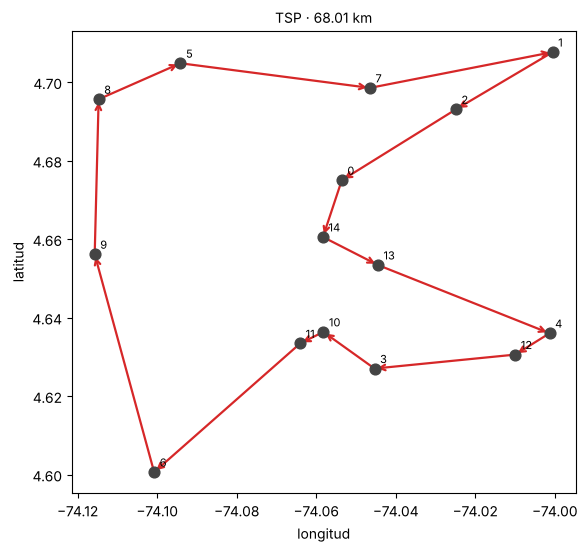

,orden,nodo,nombre,tramo_km,acumulado
0,0,0,Depósito,0.000000,0.000000
1,1,14,Cliente 14,2.198528,2.198528
2,2,13,Cliente 13,2.242739,4.441267
3,3,4,Cliente 4,6.708659,11.149926
4,4,12,Cliente 12,1.469998,12.619924
5,5,3,Cliente 3,5.126402,17.746327
6,6,10,Cliente 10,2.293772,20.040099
7,7,11,Cliente 11,0.944606,20.984705
8,8,6,Cliente 6,7.101424,28.086129
9,9,9,Cliente 9,8.309654,36.395783


In [3]:
t = og.tsp(red, origen=0)
print(t.resumen()); print("Cortes de subtour agregados:", t.extra["cortes"])
fig, ax = plt.subplots(figsize=(6.5, 6)); og.dibujar(red, t, ax=ax, titulo=f"TSP · {t.objetivo:.2f} km"); plt.show()
t.tablas["ruta"]

### 3.2 Variantes del TSP

In [4]:
variantes = {
    "circuito (regresa al origen)":          og.tsp(red, 0, "ciclo"),
    "camino abierto desde el origen":        og.tsp(red, 0, "abierto"),
    "camino del nodo 0 al nodo 14":          og.tsp(red, 0, "fijo", fin=14),
    "camino libre (inicio y fin libres)":    og.tsp(red, modo="libre"),
}
pd.DataFrame([{"variante": k, "distancia": round(v.objetivo, 3), "estado": v.estado, "seg": v.segundos,
               "recorrido": " → ".join(map(str, v.rutas[0]))} for k, v in variantes.items()])

,variante,distancia,estado,seg,recorrido
0,circuito (regresa al origen),68.014,óptimo,0.081,0 → 14 → 13 → 4 → 12 → 3 → 10 → 11 → 6 → 9 → 8...
1,camino abierto desde el origen,59.586,óptimo,0.055,0 → 14 → 13 → 4 → 12 → 3 → 10 → 11 → 6 → 9 → 8...
2,camino del nodo 0 al nodo 14,65.816,óptimo,0.074,0 → 2 → 1 → 7 → 5 → 8 → 9 → 6 → 11 → 10 → 3 → ...
3,camino libre (inicio y fin libres),56.212,óptimo,0.046,5 → 8 → 9 → 6 → 11 → 10 → 3 → 12 → 4 → 13 → 14...


### 3.3 Dos formulaciones del mismo TSP

In [5]:
a = og.tsp(red, 0, metodo="dfj"); b = og.tsp(red, 0, metodo="mtz")
print(f"DFJ (cortes iterativos): {a.objetivo:.3f} km en {a.segundos} s")
print(f"MTZ (un solo MILP)     : {b.objetivo:.3f} km en {b.segundos} s")

DFJ (cortes iterativos): 68.014 km en 0.076 s
MTZ (un solo MILP)     : 68.014 km en 0.34 s


## 4. m-TSP (varios viajantes)

### 4.1 Mínima distancia total

In [6]:
m3 = og.mtsp(red, 3, deposito=0)
print(m3.resumen()); m3.tablas["rutas"]

Problema : m-TSP con m=3 (MILP)
Estado   : óptimo
Objetivo : 73.853
Brecha   : 0.00e+00
Tiempo   : 0.034 s
Distancia total = 73.853; ruta más larga = 62.684


,vehículo,ruta,clientes,carga,distancia
0,1,0 → 7 → 2 → 1 → 4 → 12 → 3 → 10 → 11 → 6 → 9 →...,12,0.0,62.683981
1,2,0 → 13 → 0,1,0.0,6.771788
2,3,0 → 14 → 0,1,0.0,4.397057


Sin límites por ruta el óptimo puede dejar casi todos los clientes a un solo viajante. Se puede **balancear** con mínimo y máximo de clientes por ruta, o **minimizar la ruta más larga**.

In [7]:
casos = {
    "mínima distancia total":             og.mtsp(red, 3, 0),
    "balanceado: 4 a 5 clientes por ruta": og.mtsp(red, 3, 0, lmin=4, lmax=5),
    "minimizar la ruta más larga":         og.mtsp(red, 3, 0, objetivo="maximo"),
    "rutas abiertas (no regresan)":        og.mtsp(red, 3, 0, lmin=4, lmax=5, abierto=True),
}
pd.DataFrame([{"caso": k, "estado": v.estado, "distancia total": round(v.extra["total"], 3),
               "ruta más larga": round(v.tablas["rutas"]["distancia"].max(), 3),
               "clientes por ruta": v.tablas["rutas"]["clientes"].tolist(), "seg": v.segundos} for k, v in casos.items()])

,caso,estado,distancia total,ruta más larga,clientes por ruta,seg
0,mínima distancia total,óptimo,73.853,62.684,"[12, 1, 1]",0.026
1,balanceado: 4 a 5 clientes por ruta,óptimo,84.699,37.834,"[5, 5, 4]",1.246
2,minimizar la ruta más larga,óptimo,88.389,29.799,"[4, 6, 4]",26.399
3,rutas abiertas (no regresan),óptimo,58.614,24.532,"[5, 5, 4]",0.764


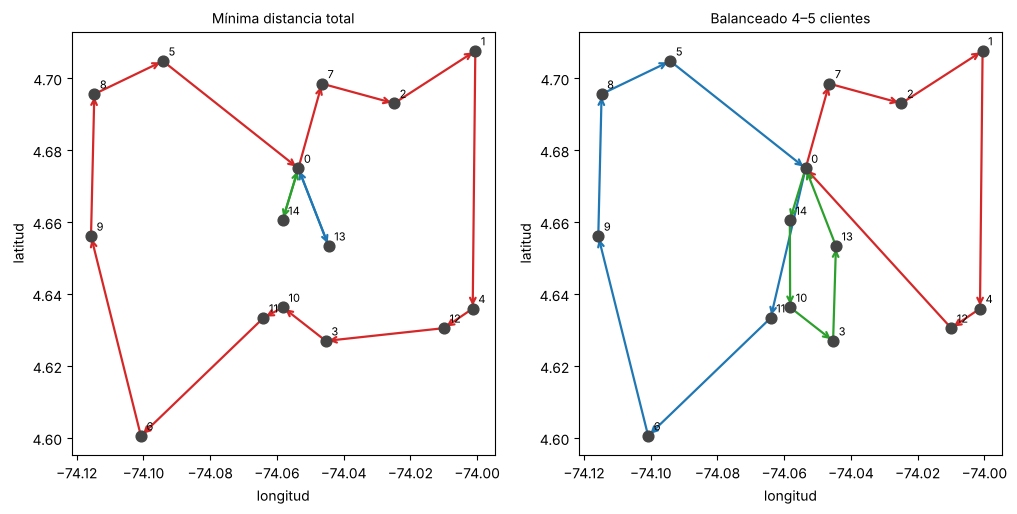

,vehículo,ruta,clientes,carga,distancia
0,1,0 → 7 → 2 → 1 → 4 → 12 → 0,5,0.0,31.673659
1,2,0 → 11 → 6 → 9 → 8 → 5 → 0,5,0.0,37.833507
2,3,0 → 14 → 10 → 3 → 13 → 0,4,0.0,15.191711


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
og.dibujar(red, casos["mínima distancia total"], ax=axes[0], titulo="Mínima distancia total")
og.dibujar(red, casos["balanceado: 4 a 5 clientes por ruta"], ax=axes[1], titulo="Balanceado 4–5 clientes")
plt.show()
casos["balanceado: 4 a 5 clientes por ruta"].tablas["rutas"]

### 4.2 Varios depósitos y VRP con capacidad (extensiones del m-TSP)

In [9]:
# cada viajante sale y regresa a su propio depósito (nodos 0 y 7)
md_ = og.vrp(red, 2, deposito=[0, 7], lmin=4, problema="m-TSP con 2 depósitos")
print(md_.resumen()); print(md_.tablas["rutas"].to_string(index=False))

# VRP con capacidad: 3 vehículos de capacidad 35 y la demanda de cada punto (columna 'demanda')
cv = og.cvrp(red, 3, 35, deposito=0, tiempo=60)
print("\n", cv.resumen()); cv.tablas["rutas"]

Problema : m-TSP con 2 depósitos
Estado   : óptimo
Objetivo : 71.003
Brecha   : 0.00e+00
Tiempo   : 9.028 s
Distancia total = 71.003; ruta más larga = 57.305
 vehículo                                       ruta  clientes  carga  distancia
        1                  0 → 13 → 10 → 11 → 14 → 0         4    0.0  13.698166
        2 7 → 5 → 8 → 9 → 6 → 3 → 12 → 4 → 1 → 2 → 7         9    0.0  57.305043



 Problema : CVRP (MILP)
Estado   : óptimo
Objetivo : 85.245
Brecha   : 0.00e+00
Tiempo   : 32.077 s
Distancia total = 85.245; ruta más larga = 40.421


,vehículo,ruta,clientes,carga,distancia
0,1,0 → 13 → 12 → 4 → 1 → 2 → 7 → 0,6,33.0,32.044205
1,2,0 → 3 → 6 → 9 → 8 → 5 → 0,5,35.0,40.420893
2,3,0 → 10 → 11 → 14 → 0,3,25.0,12.779516


## 5. Usar datos propios
Se aceptan **tres formatos** (CSV, TSV, Excel o texto pegado; `#` o vacío = no hay arco):

| Formato | Ejemplo | 
|---|---|
| Matriz | primera fila y columna con etiquetas; valores = distancia/costo |
| Aristas | columnas `origen, destino, costo` |
| Coordenadas | columnas `lat, lon` (+ `id, nombre, demanda`); distancia haversine en km × factor |

In [10]:
# a) desde un archivo (cambie la ruta por la suya)
mi_red = og.cargar("datos/ejemplo_matriz.csv")
print(mi_red)
print(og.tsp(mi_red, origen=1).resumen())

Red('datos/ejemplo_matriz.csv': 7 nodos, 42 arcos, no dirigida)
Problema : TSP (circuito) - MILP DFJ
Estado   : óptimo
Objetivo : 54.8
Brecha   : 0.00e+00
Tiempo   : 0.024 s


In [11]:
# b) pegando una matriz (copiada de Excel / Grafos)  — '#' = sin arco
texto = '''\t1\t2\t3\t4\t5
1\t#\t12\t10\t#\t12
2\t12\t#\t8\t12\t#
3\t10\t8\t#\t11\t3
4\t#\t12\t11\t#\t11
5\t12\t#\t3\t11\t#'''
r5 = og.cargar(texto)
print(og.tsp(r5, 1).resumen())

Problema : TSP (circuito) - MILP DFJ
Estado   : óptimo
Objetivo : 48.0
Brecha   : 0.00e+00
Tiempo   : 0.009 s


In [12]:
# c) con coordenadas propias (distancia en línea recta × factor de rodeo) o con una lista de aristas
r_c = og.Red.desde_coordenadas([4.60, 4.65, 4.70, 4.62], [-74.10, -74.05, -74.12, -74.15], metrica="haversine", factor=1.3)
r_a = og.Red.desde_aristas([(1,2,7),(2,3,9),(3,4,4),(4,1,6),(1,3,10),(2,4,8)])
print(og.tsp(r_c, 1).objetivo, og.tsp(r_a, 1).objetivo)

42.720831083317066 26.0


In [13]:
# resultados a Excel
t.a_excel("resultado_tsp.xlsx"); m3.a_excel("resultado_mtsp.xlsx")
print("Archivos creados: resultado_tsp.xlsx, resultado_mtsp.xlsx")

Archivos creados: resultado_tsp.xlsx, resultado_mtsp.xlsx


## 6. Formulaciones
Sea $c_{ij}$ la distancia del arco $(i,j)$, $n$ el número de nodos y $0$ el depósito.

**TSP.** $x_{ij}\in\{0,1\}$: $\min\sum c_{ij}x_{ij}$ sujeto a $\sum_j x_{ij}=1$ y $\sum_i x_{ij}=1$ para todo nodo.
Eliminación de subtours (Dantzig–Fulkerson–Johnson): $\sum_{i,j\in S}x_{ij}\le |S|-1$ para todo subconjunto $S$; se agregan solo los violados por la solución actual y se resuelve de nuevo hasta obtener un único circuito.
Alternativa compacta (Miller–Tucker–Zemlin): $u_i-u_j+(n-1)x_{ij}\le n-2$, $1\le u_i\le n-1$.
Los caminos abiertos se modelan con un nodo ficticio de costo cero.

**m-TSP (2 índices).** $x_{ij}\in\{0,1\}$; cada cliente tiene un arco de entrada y uno de salida; el depósito emite exactamente $m$ rutas:
$\sum_j x_{0j}=\sum_i x_{i0}=m$; subtours $\sum_{i,j\in S}x_{ij}\le|S|-1$ para $S$ sin depósito; el número de clientes por ruta se controla con un contador de posición $p_i$:
$p_j=p_i+1$ si $x_{ij}=1$, $p_i=1$ si sale del depósito, $l_{\min}\le p_i\le l_{\max}$ al terminar la ruta.

**m-TSP con índice de vehículo** (objetivo «ruta más larga», varios depósitos, distancia máxima): $x_{ijk}$, $y_{ik}$ (cliente $i$ en el vehículo $k$);
$\sum_k y_{ik}=1$; $\sum_j x_{jik}=\sum_j x_{ijk}=y_{ik}$; $\min z$ con $z\ge\sum c_{ij}x_{ijk}\ \forall k$.

**CVRP.** Se agrega $\sum_i q_i y_{ik}\le Q$ y variables de carga acumulada tipo MTZ.

## 7. Límites y buenas prácticas
* Los modelos son **exactos**: el tiempo crece con el número de puntos. TSP de 25–50 puntos suele resolver en segundos; m-TSP con límites de balance, objetivo de ruta más larga y CVRP son bastante más difíciles. Use `tiempo=` y revise la `brecha`.
* Un estado *«límite de tiempo»* entrega una solución factible **no probada óptima**; la brecha dice qué tan lejos puede estar.
* Las matrices se usan tal cual: con distancias asimétricas o que no cumplen la desigualdad triangular el modelo igualmente es correcto.
* Las coordenadas con haversine dan distancia en línea recta; use `factor` (p. ej. 1.3) o una matriz por carretera si necesita distancias reales.